# Random Forest Model for UFC Winner Prediction

This notebook builds a Random Forest classifier using the processed fight datasets. Random Forests are an ensemble of decision trees that average predictions to reduce overfitting and provide built-in feature importance rankings.

## Imports: Libraries Used in This Notebook

This code block imports all required packages for:
1. Data loading and manipulation (`pandas`, `numpy`).
2. Plotting (`matplotlib`, `seaborn`).
3. Model building (`RandomForestClassifier`).
4. Hyperparameter tuning (`RandomizedSearchCV`).
5. Model evaluation (`accuracy`, `precision`, `recall`, `F1`, `ROC-AUC`, confusion matrix, classification report).
6. Saving trained models (`joblib`).

In [2]:
from pathlib import Path

import numpy as np
import joblib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import randint

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
)

## Paths and Data Loading

This code block defines project/data/model paths, reads the train/validation/test processed CSV files, and prints their shapes so you can verify the splits loaded correctly.

In [3]:
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(DATA_DIR / "fights_training.csv")
val_df   = pd.read_csv(DATA_DIR / "fights_validation.csv")
test_df  = pd.read_csv(DATA_DIR / "fights_testing.csv")

print(f"Train:      {train_df.shape}")
print(f"Validation: {val_df.shape}")
print(f"Test:       {test_df.shape}")

Train:      (7468, 46)
Validation: (1066, 46)
Test:       (2136, 46)


## Define Target, Features, and Split X / y

Random Forests do not require feature scaling, so no StandardScaler is used.

In [4]:
TARGET = "winner"
features = [col for col in train_df.columns if col != TARGET]

X_train = train_df[features]
y_train = train_df[TARGET]

X_val = val_df[features]
y_val = val_df[TARGET]

X_test = test_df[features]
y_test = test_df[TARGET]

print(f"Features: {len(features)}")
print(features)

Features: 45
['mens_class_encoded', 'womens_class_encoded', 'stance_matchup_Orthodox_vs_Orthodox', 'stance_matchup_Orthodox_vs_Other', 'stance_matchup_Orthodox_vs_Southpaw', 'stance_matchup_Orthodox_vs_Switch', 'stance_matchup_Other_vs_Orthodox', 'stance_matchup_Other_vs_Southpaw', 'stance_matchup_Southpaw_vs_Orthodox', 'stance_matchup_Southpaw_vs_Other', 'stance_matchup_Southpaw_vs_Southpaw', 'stance_matchup_Southpaw_vs_Switch', 'stance_matchup_Switch_vs_Orthodox', 'stance_matchup_Switch_vs_Southpaw', 'stance_matchup_Switch_vs_Switch', 'diff_fighter_dob', 'diff_height_cm', 'diff_knockdowns', 'diff_sig_strike_atts', 'diff_sig_strikes', 'diff_tot_strike_atts', 'diff_tot_strikes', 'diff_takedown_atts', 'diff_takedowns', 'diff_submissions', 'diff_reversals', 'diff_ctrl_time', 'diff_head_strike_atts', 'diff_head_strikes', 'diff_body_strike_atts', 'diff_body_strikes', 'diff_leg_strike_atts', 'diff_leg_strikes', 'diff_dist_strike_atts', 'diff_dist_strikes', 'diff_clinch_atts', 'diff_clinchs'

## Baseline Random Forest

Train a default Random Forest on the training set and evaluate on the validation set to establish a pre-tuning benchmark.

In [5]:
baseline_rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
baseline_rf.fit(X_train, y_train)

baseline_val_pred = baseline_rf.predict(X_val)
baseline_val_acc  = accuracy_score(y_val, baseline_val_pred)
print(f"Baseline validation accuracy: {baseline_val_acc:.4f}")

Baseline validation accuracy: 0.6107


## Hyperparameter Tuning with RandomizedSearchCV

A randomized search samples `n_iter` combinations from the parameter distributions and uses 5-fold cross-validation on the training set to identify the best settings. This is more efficient than an exhaustive grid search.

In [6]:
param_distributions = {
    "n_estimators":      randint(100, 601),
    "max_depth":         [None, 5, 10, 15, 20, 25],
    "min_samples_split": randint(2, 21),
    "min_samples_leaf":  randint(1, 11),
    "max_features":      ["sqrt", "log2", 0.5],
    "class_weight":      [None, "balanced"],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_distributions,
    n_iter=60,
    cv=5,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1,
    verbose=1,
)

rf_search.fit(X_train, y_train)

print("\nBest parameters:")
print(rf_search.best_params_)
print(f"Best CV accuracy: {rf_search.best_score_:.4f}")

Fitting 5 folds for each of 60 candidates, totalling 300 fits


/opt/homebrew/Caskroom/miniconda/base/envs/UFC/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/UFC/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/homebrew/Caskroom/miniconda/base/envs/UFC/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/


Best parameters:
{'class_weight': None, 'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 7, 'min_samples_split': 15, 'n_estimators': 257}
Best CV accuracy: 0.5786


## Evaluate the Tuned Model on Validation and Test Sets

In [7]:
best_rf = rf_search.best_estimator_

val_pred  = best_rf.predict(X_val)
val_prob  = best_rf.predict_proba(X_val)[:, 1]

test_pred = best_rf.predict(X_test)
test_prob = best_rf.predict_proba(X_test)[:, 1]

val_metrics = {
    "accuracy":  accuracy_score(y_val, val_pred),
    "precision": precision_score(y_val, val_pred, zero_division=0),
    "recall":    recall_score(y_val, val_pred, zero_division=0),
    "f1":        f1_score(y_val, val_pred, zero_division=0),
    "log_loss":  log_loss(y_val, val_prob),
    "roc_auc":   roc_auc_score(y_val, val_prob),
}

test_metrics = {
    "accuracy":  accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred, zero_division=0),
    "recall":    recall_score(y_test, test_pred, zero_division=0),
    "f1":        f1_score(y_test, test_pred, zero_division=0),
    "log_loss":  log_loss(y_test, test_prob),
    "roc_auc":   roc_auc_score(y_test, test_prob),
}

metrics_df = pd.DataFrame([val_metrics, test_metrics], index=["validation", "test"])
display(metrics_df)

print("\nValidation classification report:")
print(classification_report(y_val, val_pred, digits=4))

print("\nTest classification report:")
print(classification_report(y_test, test_pred, digits=4))

,accuracy,precision,recall,f1,log_loss,roc_auc
validation,0.606942,0.607143,0.606004,0.606573,0.657672,0.644925
test,0.627341,0.627820,0.625468,0.626642,0.643771,0.679430



Validation classification report:
              precision    recall  f1-score   support

           0     0.6067    0.6079    0.6073       533
           1     0.6071    0.6060    0.6066       533

    accuracy                         0.6069      1066
   macro avg     0.6069    0.6069    0.6069      1066
weighted avg     0.6069    0.6069    0.6069      1066


Test classification report:
              precision    recall  f1-score   support

           0     0.6269    0.6292    0.6280      1068
           1     0.6278    0.6255    0.6266      1068

    accuracy                         0.6273      2136
   macro avg     0.6273    0.6273    0.6273      2136
weighted avg     0.6273    0.6273    0.6273      2136



## Save Validation Predictions to CSV

In [8]:
validation_output_path = DATA_DIR / "random_forest_validation_predictions.csv"

validation_results = X_val.reset_index(drop=True).copy()
validation_results["actual_label"]     = y_val.reset_index(drop=True)
validation_results["predicted_label"]  = val_pred
validation_results["prob_fighter_a_win"] = val_prob
validation_results["prob_fighter_b_win"] = 1 - val_prob
validation_results["correct"] = (validation_results["actual_label"] == validation_results["predicted_label"]).astype(int)

validation_results.to_csv(validation_output_path, index=False)
print(f"Saved validation predictions to: {validation_output_path}")

Saved validation predictions to: /Users/connormcilhinney/Desktop/GithubRepos/Machine-Learning-Project/data/processed/random_forest_validation_predictions.csv


## ROC Curve

Plots the ROC curve for both the validation and test splits. Curves closer to the top-left corner indicate stronger class separation.

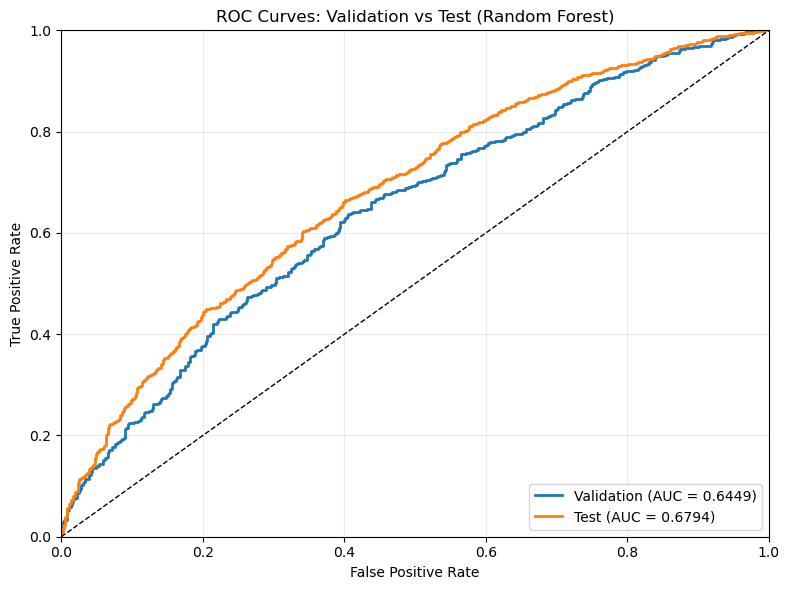

In [ ]:
val_auc  = roc_auc_score(y_val, val_prob)
test_auc = roc_auc_score(y_test, test_prob)

val_fpr,  val_tpr,  _ = roc_curve(y_val,  val_prob)
test_fpr, test_tpr, _ = roc_curve(y_test, test_prob)

plt.figure(figsize=(8, 6))
plt.plot(val_fpr,  val_tpr,  linewidth=2, label=f"Validation (AUC = {val_auc:.4f})")
plt.plot(test_fpr, test_tpr, linewidth=2, label=f"Test (AUC = {test_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Validation vs Test (Random Forest)")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Confusion Matrix

Shows true vs predicted labels on the test set. Rows are actual labels; columns are predicted labels.

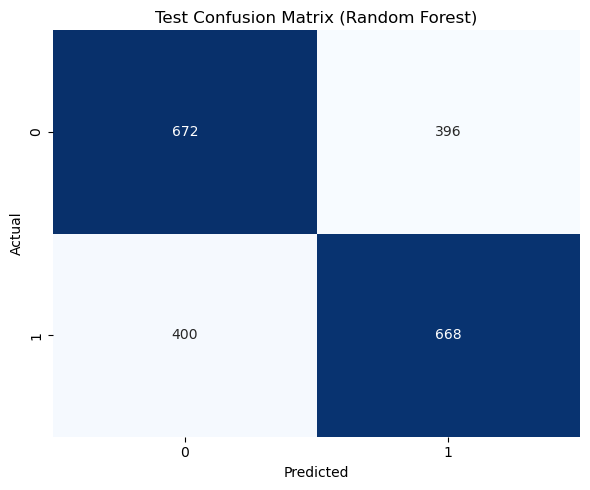

In [10]:
cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Test Confusion Matrix (Random Forest)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## Feature Importance

Random Forests compute mean decrease in impurity (Gini importance) across all trees for each feature. Higher values mean the feature was used more often and produced larger splits.

/var/folders/g3/zmhjghbx599gjzn3783w82mc0000gn/T/ipykernel_22592/1709720460.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_feats, x="importance", y="feature", palette="Blues_r")


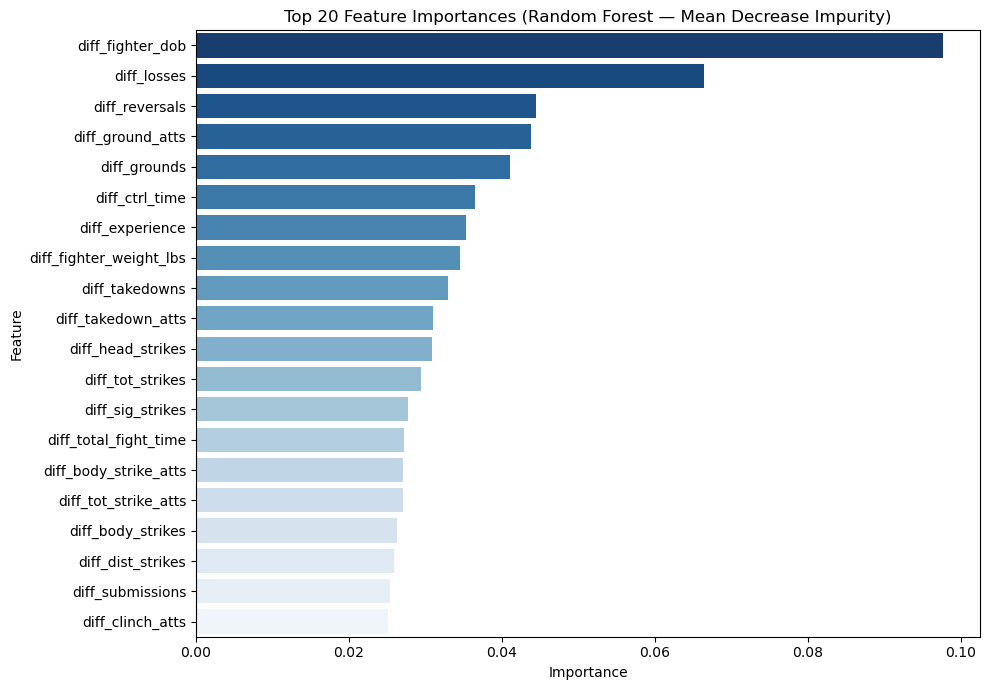


Top 20 features:


,feature,importance
0,diff_fighter_dob,0.097639
1,diff_losses,0.066453
2,diff_reversals,0.044512
3,diff_ground_atts,0.043820
4,diff_grounds,0.041001
5,diff_ctrl_time,0.036474
6,diff_experience,0.035346
7,diff_fighter_weight_lbs,0.034458
8,diff_takedowns,0.033002
9,diff_takedown_atts,0.030930


In [11]:
importances = best_rf.feature_importances_
feat_imp_df = (
    pd.DataFrame({"feature": features, "importance": importances})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

top_n = 20
top_feats = feat_imp_df.head(top_n)

plt.figure(figsize=(10, 7))
sns.barplot(data=top_feats, x="importance", y="feature", palette="Blues_r")
plt.title(f"Top {top_n} Feature Importances (Random Forest — Mean Decrease Impurity)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print(f"\nTop {top_n} features:")
display(top_feats)

## Feature-Focused Accuracy Plots

Bins the top features by value range and plots per-bin accuracy on the test set to reveal where the model performs best and worst.

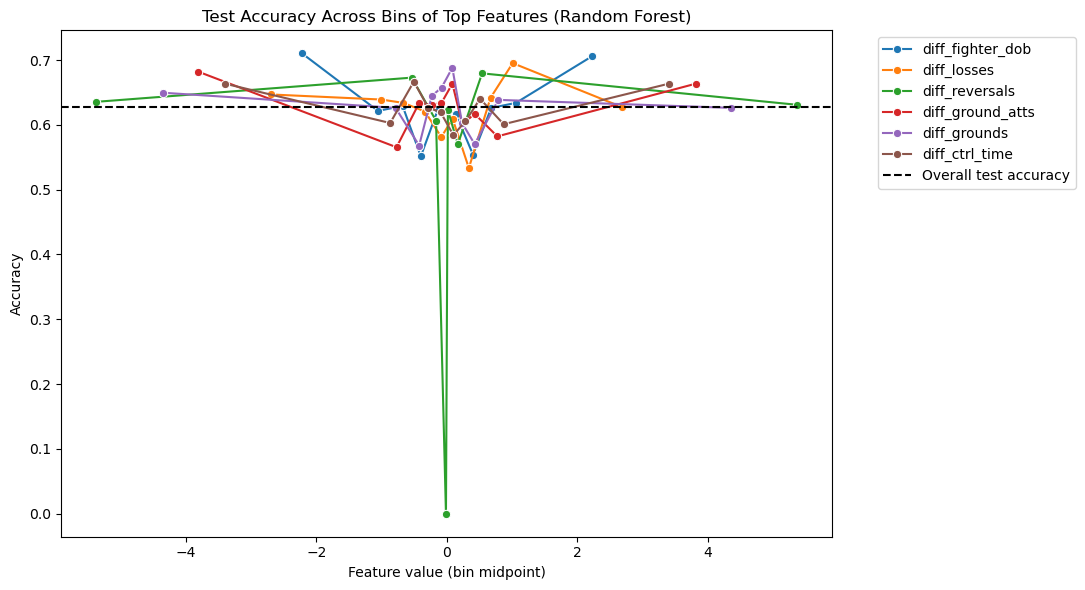

In [12]:
top_plot_n = 6
top_plot_features = top_feats.head(top_plot_n)["feature"].tolist()

plot_df = X_test[top_plot_features].copy()
plot_df["correct"] = (test_pred == y_test.to_numpy()).astype(int)

binned_rows = []
for feature in top_plot_features:
    try:
        bins = pd.qcut(plot_df[feature], q=10, duplicates="drop")
    except ValueError:
        continue

    feature_bins = pd.DataFrame({"bin": bins, "correct": plot_df["correct"]})
    summary = feature_bins.groupby("bin", observed=False)["correct"].mean().reset_index(name="accuracy")
    summary["feature"]  = feature
    summary["bin_mid"]  = summary["bin"].apply(lambda interval: interval.mid)
    binned_rows.append(summary)

if binned_rows:
    binned_accuracy = pd.concat(binned_rows, ignore_index=True)

    plt.figure(figsize=(11, 6))
    sns.lineplot(data=binned_accuracy, x="bin_mid", y="accuracy", hue="feature", marker="o")
    plt.axhline(accuracy_score(y_test, test_pred), color="black", linestyle="--", label="Overall test accuracy")
    plt.title("Test Accuracy Across Bins of Top Features (Random Forest)")
    plt.xlabel("Feature value (bin midpoint)")
    plt.ylabel("Accuracy")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
else:
    print("Could not build binned feature plot (insufficient unique values).")

## Save the Trained Model

Saves the best Random Forest pipeline as a `.joblib` artifact for reuse in later notebooks or scripts.

In [13]:
model_path = MODEL_DIR / "random_forest.joblib"
joblib.dump(best_rf, model_path)
print(f"Saved model to: {model_path}")

Saved model to: /Users/connormcilhinney/Desktop/GithubRepos/Machine-Learning-Project/models/random_forest.joblib
